# 03 · Wstępne przetwarzanie sygnału EEG w MNE-Python

**Kurs:** Praktyczna Analiza Danych Eye-Tracking i EEG w Pythonie

Surowy zapis EEG zawiera nie tylko aktywność mózgu, ale też zakłócenia: szum sieci energetycznej, wolne dryfy, mrugnięcia, ruchy gałek ocznych, napięcie mięśni czy uszkodzone elektrody. W tym notebooku zbudujemy standardowy potok (*pipeline*) wstępnego przetwarzania:

1. wczytanie danych i praca z obiektem `mne.io.Raw`,
2. filtracja sieciowa (*notch*),
3. wykrywanie i interpolacja złych kanałów (PyPREP),
4. filtracja pasmowoprzepustowa 1–40 Hz,
5. re-referencja do średniej (*average reference*),
6. analiza składowych niezależnych (ICA) – usuwanie mrugnięć i artefaktów mięśniowych,
7. zapis oczyszczonych danych (oraz – dla chętnych – zapis w standardzie BIDS).

**Dane:** zestaw `sample` z MNE-Python – jednoczesny zapis MEG i EEG (60 elektrod) podczas prezentacji bodźców słuchowych i wzrokowych (Gramfort i in., 2013). Korzystamy tylko z kanałów EEG.

**Szacowany czas:** ok. 90–120 minut.

> ⏳ **Pierwsze uruchomienie:** zestaw `sample` waży ok. 1,6 GB. W Codespaces pobiera się automatycznie w tle podczas tworzenia środowiska. Jeśli jeszcze go nie ma, komórka z `data_path()` pobierze go sama – zajmie to kilka minut.

## 0. Przygotowanie środowiska

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
from mne.preprocessing import ICA
from pyprep import NoisyChannels

KATALOG_GLOWNY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
WYNIKI = KATALOG_GLOWNY / "wyniki"
WYNIKI.mkdir(exist_ok=True)

mne.set_log_level("WARNING")  # mniej komunikatów; ustaw "INFO", aby zobaczyć szczegóły obliczeń
mne.viz.set_browser_backend("matplotlib")  # przebiegi EEG jako statyczne wykresy w notebooku
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"])})
print("Wersja MNE-Python:", mne.__version__)

Wersja MNE-Python: 1.12.1


## 1. Wczytanie danych – obiekt `mne.io.Raw`

`mne.datasets.sample.data_path()` zwraca ścieżkę do zestawu `sample` (i w razie potrzeby go pobiera). Plik `.fif` wczytujemy funkcją `mne.io.read_raw_fif`. Parametr `preload=False` oznacza, że na razie wczytujemy tylko **nagłówek** – same próbki zostaną załadowane do pamięci dopiero wtedy, gdy będą potrzebne.

In [2]:
katalog_sample = mne.datasets.sample.data_path()
plik_raw = katalog_sample / "MEG" / "sample" / "sample_audvis_raw.fif"
raw = mne.io.read_raw_fif(plik_raw, preload=False)
raw

<Raw | sample_audvis_raw.fif, 376 x 166800 (277.7 s), ~3.2 MiB, data not loaded>

Najważniejsze metadane przechowuje słownik `raw.info`:

In [3]:
print(f"Częstotliwość próbkowania: {raw.info['sfreq']:.1f} Hz")
print(f"Długość nagrania: {raw.times[-1]:.1f} s")
print(f"Filtry sprzętowe: {raw.info['highpass']:.1f}–{raw.info['lowpass']:.1f} Hz")
print("Liczba kanałów według typu:", dict(Counter(raw.get_channel_types())))
print("Kanały oznaczone jako złe:", raw.info["bads"])

Częstotliwość próbkowania: 600.6 Hz
Długość nagrania: 277.7 s
Filtry sprzętowe: 0.1–172.2 Hz
Liczba kanałów według typu: {'grad': 204, 'mag': 102, 'stim': 9, 'eeg': 60, 'eog': 1}
Kanały oznaczone jako złe: ['MEG 2443', 'EEG 053']


Zostawiamy tylko kanały EEG, kanał EOG (elektrookulogram – rejestruje ruchy oczu i mrugnięcia) oraz kanały wyzwalaczy (*stim*), w których zapisano momenty pojawienia się bodźców. Dopiero teraz ładujemy dane do pamięci.

In [4]:
raw.pick(["eeg", "eog", "stim"]).load_data()
print("Po wyborze kanałów:", dict(Counter(raw.get_channel_types())))
print("Kanały oznaczone jako złe:", raw.info["bads"])

Po wyborze kanałów: {'stim': 9, 'eeg': 60, 'eog': 1}
Kanały oznaczone jako złe: ['EEG 053']


Pod spodem obiekt `Raw` to po prostu tablica NumPy o wymiarach *kanały × próbki*, zawsze w jednostkach **SI** (dla EEG – w woltach). Wyciągnijmy jedną sekundę z jednego kanału:

Kształt tablicy: (1, 601) | jednostka: V


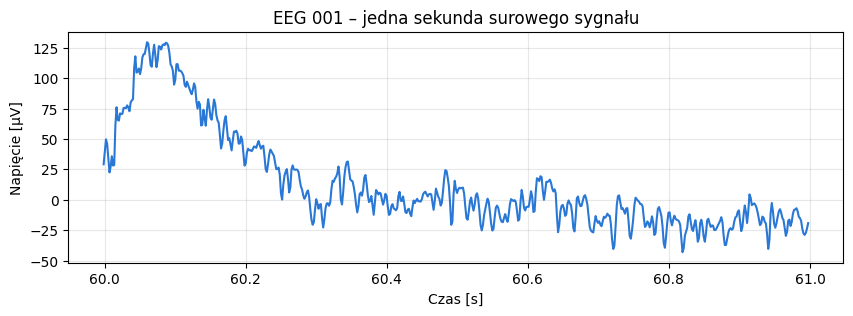

In [5]:
dane, czasy = raw.get_data(picks="EEG 001", tmin=60, tmax=61, return_times=True)
print("Kształt tablicy:", dane.shape, "| jednostka: V")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(czasy, dane[0] * 1e6)  # przeliczenie V → µV
ax.set(xlabel="Czas [s]", ylabel="Napięcie [µV]", title="EEG 001 – jedna sekunda surowego sygnału")
plt.show()

### Rozmieszczenie elektrod i przegląd sygnału

Kanały EEG w zestawie `sample` mają nazwy `EEG 001`–`EEG 060` (zamiast nazw systemu 10–20), ale ich położenie zostało zdigitalizowane, więc MNE wie, gdzie leży każda elektroda. Na czerwono zaznaczony jest kanał oznaczony jako zły.

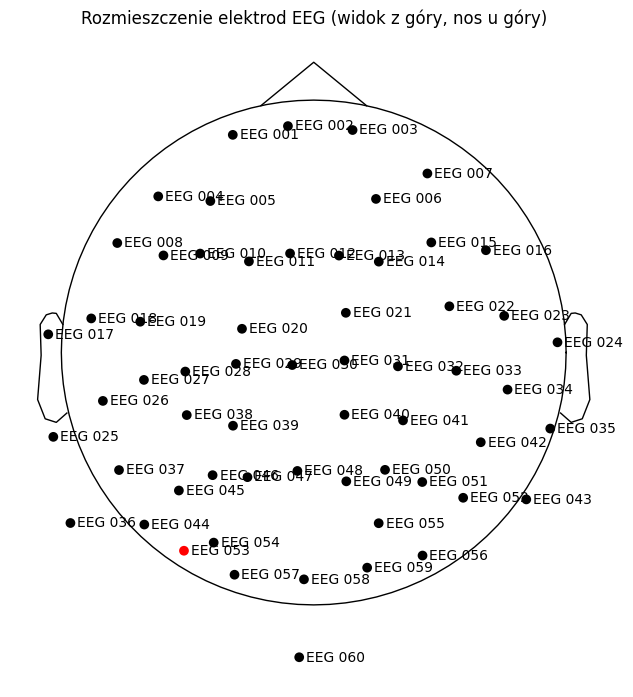

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 8.5))
raw.plot_sensors(show_names=True, axes=ax, show=False)
ax.set_title("Rozmieszczenie elektrod EEG (widok z góry, nos u góry)")
plt.show()

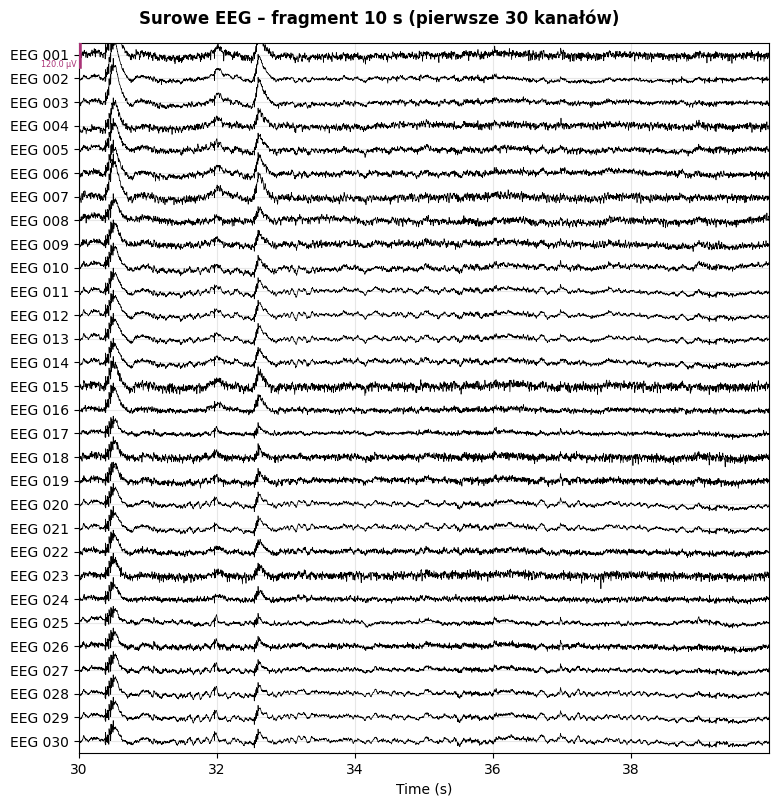

In [7]:
fig = raw.plot(start=30, duration=10, n_channels=30, scalings=dict(eeg=60e-6, eog=200e-6, stim=1),
               show_scrollbars=False, show=False)
fig.suptitle("Surowe EEG – fragment 10 s (pierwsze 30 kanałów)", y=1.01, fontweight="bold")
plt.show()

Na surowym sygnale widać wolne „falowanie” (dryfy) i duże, powolne wychylenia w kanałach czołowych i w EOG – to **mrugnięcia**. Kanał `EEG 053`, oznaczony przez autorów nagrania jako zły, jest wyszarzony.

Widmo mocy (*Power Spectral Density*, PSD) pokazuje, jak moc sygnału rozkłada się na częstotliwości. Przerywanymi liniami zaznaczono 50 Hz (sieć energetyczna w Polsce i Europie) i 60 Hz (USA).

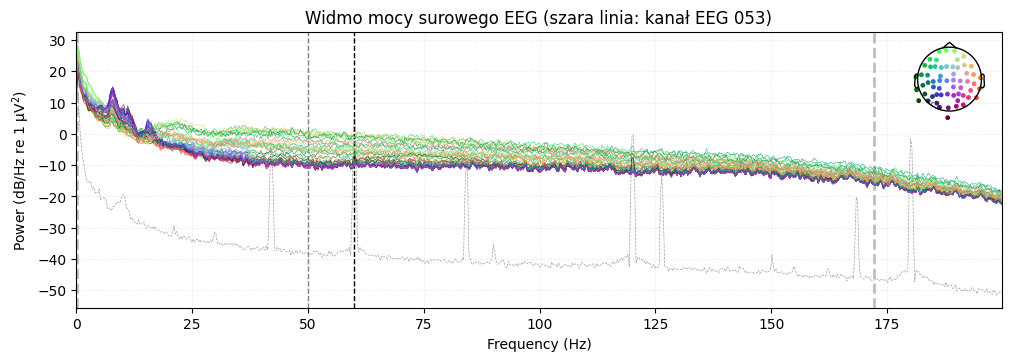

In [8]:
widmo_surowe = raw.compute_psd(fmax=200, picks="eeg")
fig = widmo_surowe.plot(picks="eeg", exclude=[], amplitude=False, show=False)
for czestotliwosc, kolor in [(50, "gray"), (60, "black")]:
    fig.axes[0].axvline(czestotliwosc, color=kolor, ls="--", lw=1)
fig.axes[0].set_title("Widmo mocy surowego EEG (szara linia: kanał EEG 053)")
plt.show()

## 2. Filtracja sieciowa (*notch*)

Przewody elektryczne w budynku indukują w elektrodach sinusoidalne zakłócenia o częstotliwości sieci energetycznej: **50 Hz w Polsce i Europie**, **60 Hz w USA**, oraz ich harmonicznych (100, 150, … lub 120, 180, … Hz). Filtr *notch* („wycinający”) usuwa bardzo wąskie pasmo wokół tych częstotliwości.

Zestaw `sample` nagrano w Martinos Center (Massachusetts General Hospital, USA), więc w widmie widać niewielki pik przy **60 Hz**, a nie przy 50 Hz. Wniosek praktyczny: **zawsze najpierw sprawdzamy widmo, a dopiero potem dobieramy filtr.**

### Demonstracja: zakłócenie 50 Hz jak w polskim laboratorium

Aby zobaczyć filtr notch w akcji, dodajmy do *kopii* danych sztuczne zakłócenie 50 Hz o amplitudzie 15 µV i usuńmy je filtrem.

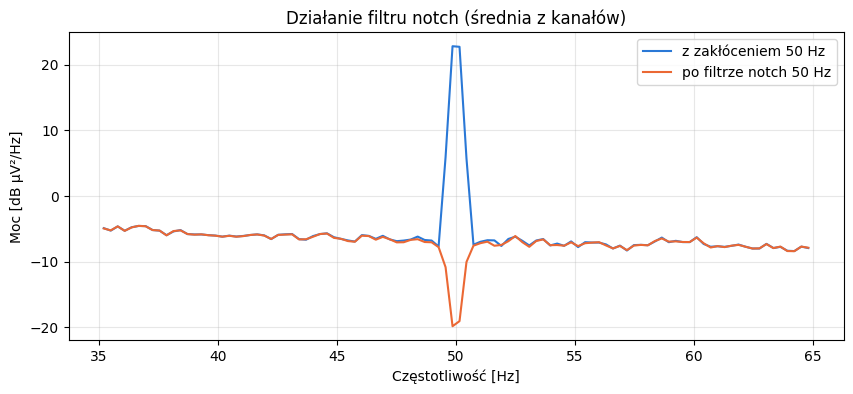

In [9]:
demo = raw.copy().pick("eeg").crop(tmax=60)
demo.apply_function(lambda x: x + 15e-6 * np.sin(2 * np.pi * 50 * demo.times))
demo_po_filtrze = demo.copy().notch_filter(freqs=[50])

fig, ax = plt.subplots(figsize=(10, 4))
for dane_demo, opis in [(demo, "z zakłóceniem 50 Hz"), (demo_po_filtrze, "po filtrze notch 50 Hz")]:
    widmo = dane_demo.compute_psd(fmin=35, fmax=65)
    ax.plot(widmo.freqs, 10 * np.log10(widmo.get_data().mean(axis=0) * 1e12), label=opis)  # V²/Hz → dB(µV²/Hz)
ax.set(xlabel="Częstotliwość [Hz]", ylabel="Moc [dB µV²/Hz]", title="Działanie filtru notch (średnia z kanałów)")
ax.legend()
plt.show()

Teraz filtr dla prawdziwych danych. Częstotliwość sieci ustawiamy w jednym miejscu – w danych z polskiego laboratorium wystarczy zmienić ją na 50 Hz.

In [10]:
CZESTOTLIWOSC_SIECI = 60  # ✏️ Hz; dane „sample” pochodzą z USA – dla nagrań z Polski ustaw 50

harmoniczne = CZESTOTLIWOSC_SIECI * np.arange(1, 4)  # np. 60, 120, 180 Hz
raw.notch_filter(freqs=harmoniczne, picks=["eeg", "eog"])
print("Usunięto zakłócenia o częstotliwościach:", harmoniczne, "Hz")

Usunięto zakłócenia o częstotliwościach: [ 60 120 180] Hz


## 3. Złe kanały: automatyczna detekcja (PyPREP) i interpolacja

Zła elektroda (odklejona, z wysoką impedancją, uszkodzona) psuje nie tylko własny kanał: przy re-referencji do średniej jej szum „rozleje się” na wszystkie pozostałe kanały. Dlatego złe kanały wykrywamy i **interpolujemy** (odtwarzamy z sąsiednich elektrod) **przed** re-referencją.

Biblioteka **PyPREP** implementuje kryteria z potoku PREP (Bigdely-Shamlo i in., 2015), m.in.:

* `deviation` – nietypowo duża lub mała amplituda,
* `correlation` – słaba korelacja z innymi kanałami,
* `hf_noise` – dużo szumu wysokoczęstotliwościowego (> 50 Hz),
* `ransac` – kanał źle przewidywany na podstawie losowych podzbiorów innych kanałów,
* `psd` – nietypowe widmo mocy.

In [11]:
detektor = NoisyChannels(raw.copy().pick("eeg"), random_state=42)
detektor.find_all_bads(ransac=True)
for kryterium, kanaly in detektor.get_bads(as_dict=True).items():
    if kanaly:
        print(f"{kryterium:20s} {sorted(kanaly)}")

bad_by_hf_noise      ['EEG 018']
bad_by_correlation   ['EEG 004', 'EEG 008']
bad_by_psd           ['EEG 001', 'EEG 004', 'EEG 005', 'EEG 007', 'EEG 008', 'EEG 009', 'EEG 015', 'EEG 018', 'EEG 023', 'EEG 034']
bad_by_manual        ['EEG 053']
bad_all              ['EEG 001', 'EEG 004', 'EEG 005', 'EEG 007', 'EEG 008', 'EEG 009', 'EEG 015', 'EEG 018', 'EEG 023', 'EEG 034', 'EEG 053']


Algorytm oznaczył sporo kanałów – głównie elektrody czołowe i skroniowe (kryterium `psd`). Zanim cokolwiek zinterpolujemy, **obejrzyjmy sygnał** (dla czytelności wyświetlamy kopię przefiltrowaną 1–40 Hz).

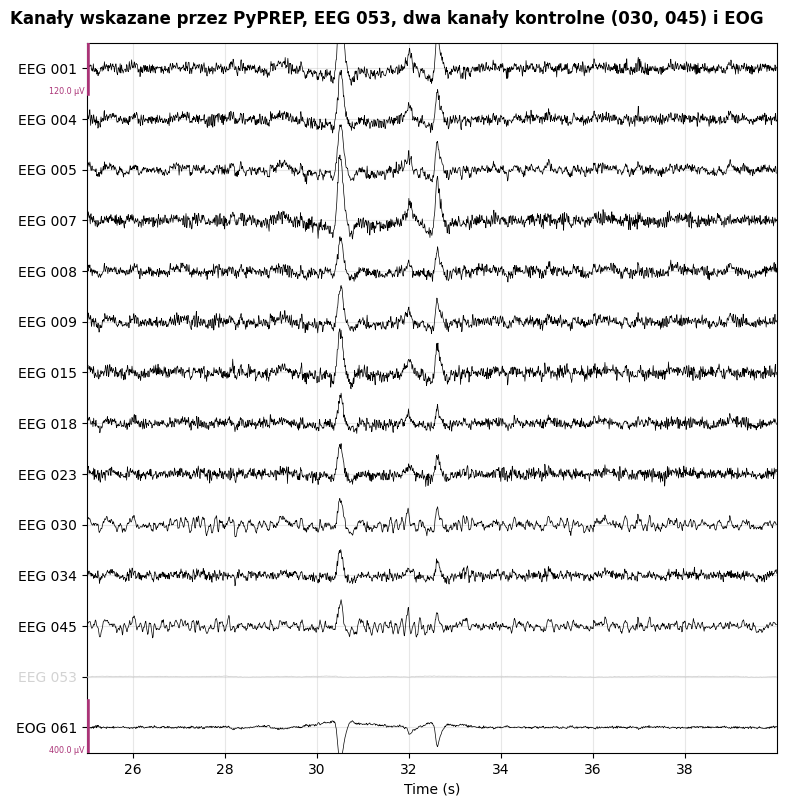

Odchylenie standardowe w paśmie 1–40 Hz: EEG 053 = 1.0 µV, mediana pozostałych kanałów = 11.1 µV


In [12]:
podejrzane = sorted(set(detektor.get_bads()) - {"EEG 053"})
podglad = raw.copy().filter(1, 40, picks=["eeg", "eog"])
fig = podglad.plot(picks=podejrzane + ["EEG 053", "EEG 030", "EEG 045", "EOG 061"], start=25, duration=15,
                   scalings=dict(eeg=60e-6, eog=200e-6), show_scrollbars=False, show=False)
fig.suptitle("Kanały wskazane przez PyPREP, EEG 053, dwa kanały kontrolne (030, 045) i EOG", y=1.01,
             fontweight="bold")
plt.show()

pozostale = [kanal for kanal in podglad.copy().pick("eeg").ch_names if kanal != "EEG 053"]
print(f"Odchylenie standardowe w paśmie 1–40 Hz: EEG 053 = {podglad.get_data(picks='EEG 053').std() * 1e6:.1f} µV, "
      f"mediana pozostałych kanałów = {np.median(podglad.get_data(picks=pozostale).std(axis=1)) * 1e6:.1f} µV")

Interpretacja:

* Kanał **EEG 053** jest wyraźnie uszkodzony – jego sygnał jest prawie płaski (wielokrotnie mniejsza amplituda niż w innych kanałach).
* Pozostałe podejrzane kanały wyglądają poprawnie. Ich „nietypowość” wynika z **mrugnięć** (duże, wolne wychylenia w kanałach czołowych) i **napięcia mięśni** czoła i skroni. To fizjologia, a nie uszkodzone elektrody – takie artefakty lepiej usunąć za pomocą ICA niż niszczyć interpolacją całe kanały.

Algorytmy automatyczne **podpowiadają**, ale decyzję podejmuje badacz (i opisuje ją w raporcie). Interpolujemy więc tylko kanał EEG 053. Interpolacja metodą *spherical splines* wykorzystuje położenia elektrod.

In [13]:
raw.info["bads"] = ["EEG 053"]  # ✏️ spróbuj też: detektor.get_bads()
raw.interpolate_bads(reset_bads=True)
print(f"Po interpolacji – odchylenie standardowe EEG 053: {raw.get_data(picks='EEG 053').std() * 1e6:.1f} µV")
print("Kanały oznaczone jako złe:", raw.info["bads"])

Po interpolacji – odchylenie standardowe EEG 053: 18.1 µV
Kanały oznaczone jako złe: []


## 4. Filtracja pasmowoprzepustowa 1–40 Hz

* **Filtr górnoprzepustowy (1 Hz)** usuwa wolne dryfy (pot, ruchy kabli, polaryzacja elektrod). Odcięcie 1 Hz jest też zalecane przed ICA (Winkler i in., 2015). Uwaga: w analizach ERP często stosuje się łagodniejsze 0,1 Hz, bo filtr 1 Hz może zniekształcać wolne komponenty (np. P300).
* **Filtr dolnoprzepustowy (40 Hz)** usuwa szybkie zakłócenia (m.in. większość aktywności mięśniowej i resztki szumu sieciowego).

MNE domyślnie projektuje filtr **FIR o zerowej fazie**, który nie przesuwa sygnału w czasie. Obejrzyjmy jego charakterystykę: odpowiedź impulsową (w czasie) i odpowiedź częstotliwościową.

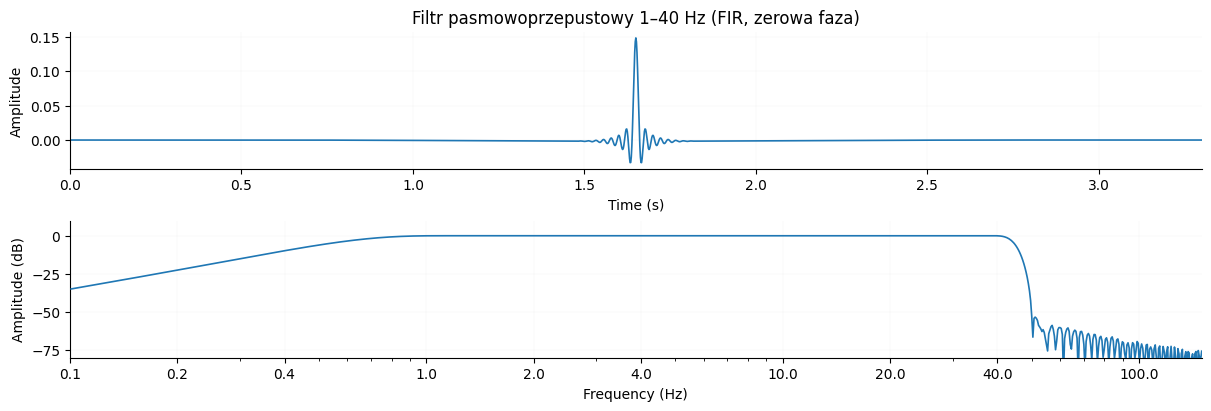

In [14]:
filtr = mne.filter.create_filter(None, raw.info["sfreq"], l_freq=1.0, h_freq=40.0)
fig = mne.viz.plot_filter(filtr, raw.info["sfreq"], flim=(0.1, 150), plot=("time", "magnitude"),
                          title="Filtr pasmowoprzepustowy 1–40 Hz (FIR, zerowa faza)")

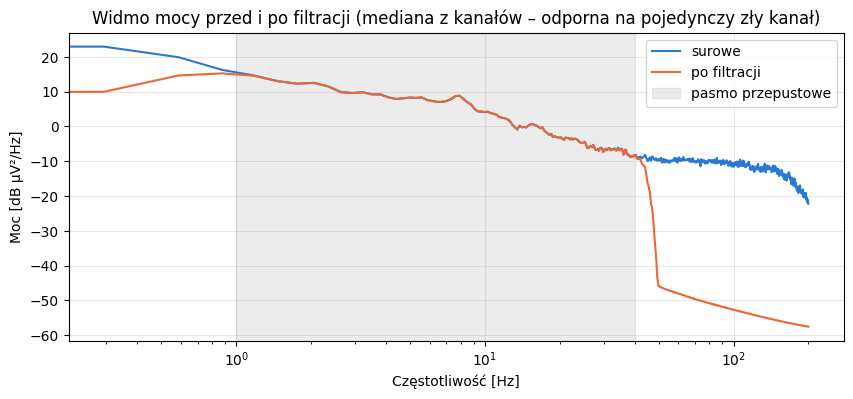

In [15]:
raw_przed_pasmem = raw.copy()  # kopia sprzed filtracji pasmowej – przyda się do ICA
raw.filter(l_freq=1.0, h_freq=40.0, picks=["eeg", "eog"])

fig, ax = plt.subplots(figsize=(10, 4))
for widmo, opis in [(widmo_surowe, "surowe"), (raw.compute_psd(fmax=200, picks="eeg"), "po filtracji")]:
    ax.plot(widmo.freqs, 10 * np.log10(np.median(widmo.get_data(), axis=0) * 1e12), label=opis)
ax.axvspan(1, 40, color="gray", alpha=0.15, label="pasmo przepustowe")
ax.set(xscale="log", xlabel="Częstotliwość [Hz]", ylabel="Moc [dB µV²/Hz]",
       title="Widmo mocy przed i po filtracji (mediana z kanałów – odporna na pojedynczy zły kanał)")
ax.legend()
plt.show()

## 5. Re-referencja do średniej

Napięcie EEG to zawsze **różnica potencjałów** między elektrodą a elektrodą odniesienia (referencyjną). Wybór referencji zmienia kształt przebiegów i map topograficznych. Przy gęstym rozmieszczeniu elektrod (≥ 32) popularna jest **referencja do średniej**: od każdego kanału w każdej chwili odejmujemy średnią ze wszystkich kanałów EEG. Dzięki temu żadna pojedyncza elektroda nie jest uprzywilejowana.

Właśnie dlatego złe kanały trzeba było naprawić wcześniej – trafiłyby do średniej i zanieczyściły wszystkie kanały.

In [16]:
raw.set_eeg_reference("average", projection=False)

srednia = raw.get_data(picks="eeg").mean(axis=0)
print(f"Po re-referencji średnia ze wszystkich kanałów EEG wynosi ~0 (maks. |średnia| = {np.abs(srednia).max():.1e} V)")

Po re-referencji średnia ze wszystkich kanałów EEG wynosi ~0 (maks. |średnia| = 5.6e-20 V)


## 6. Analiza składowych niezależnych (ICA)

Każda elektroda rejestruje **mieszaninę** sygnałów z wielu źródeł: mózgu, oczu, mięśni. ICA (*Independent Component Analysis*) rozkłada wielokanałowy sygnał na składowe, które są możliwie **statystycznie niezależne**. Artefakty (mrugnięcia, mięśnie) mają zwykle charakterystyczne, niezależne od mózgu źródła, więc trafiają do osobnych składowych. Usuwamy je i składamy sygnał z powrotem.

**Ważny trik:** ICA dopasowujemy na kopii danych o **szerszym paśmie (1–100 Hz)**. Artefakty mięśniowe mają większość mocy powyżej 20 Hz – w danych obciętych do 40 Hz trudno je rozpoznać. Wyznaczone filtry przestrzenne można potem zastosować do danych 1–40 Hz, bo filtracja w czasie nie zmienia sposobu mieszania źródeł na elektrodach.

In [17]:
raw_do_ica = raw_przed_pasmem.copy().filter(l_freq=1.0, h_freq=100.0, picks=["eeg", "eog"])
raw_do_ica.set_eeg_reference("average", projection=False)

ica = ICA(n_components=20, method="fastica", random_state=97, max_iter="auto")
ica.fit(raw_do_ica, picks="eeg")
ica

Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,45 iterations on raw data (166800 samples)
ICA components,20
Available PCA components,60
Channel types,eeg
ICA components marked for exclusion,—


Każda składowa ma swoją **topografię** (jak bardzo „widzi” ją każda elektroda). Już na tym etapie można zgadywać: składowa z silnym polem na czole to zwykle mrugnięcia, a bardzo ogniskowe składowe na brzegach głowy często pochodzą od mięśni.

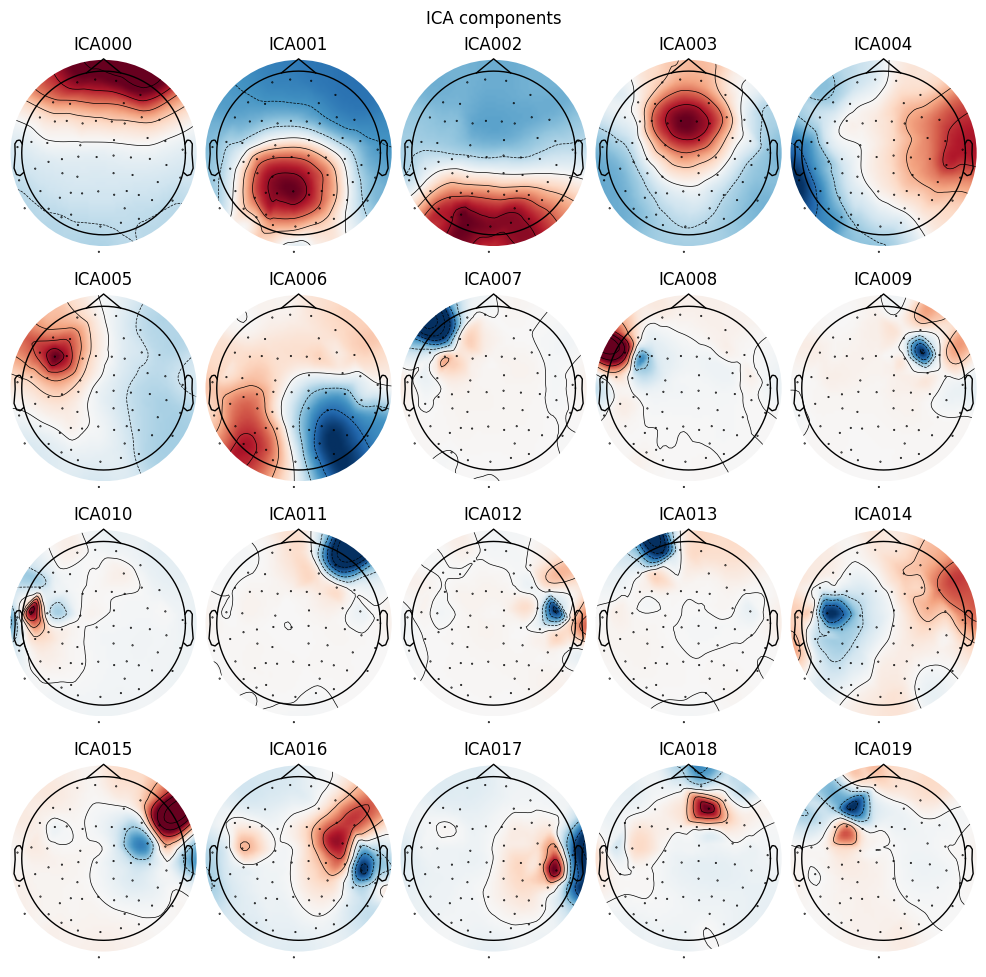

In [18]:
fig = ica.plot_components()

### Mrugnięcia: korelacja z kanałem EOG

`find_bads_eog` szuka składowych, których przebieg czasowy najsilniej koreluje z kanałem EOG.

Składowe związane z ruchami oczu i mrugnięciami: [0]


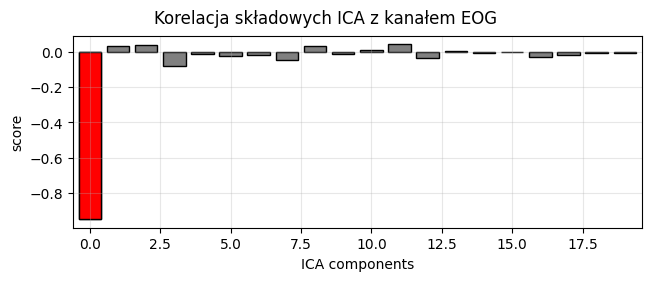

In [19]:
eog_idx, eog_wyniki = ica.find_bads_eog(raw_do_ica, ch_name="EOG 061")
eog_idx = [int(i) for i in eog_idx]  # zwykłe liczby całkowite – czytelniejszy wydruk
print("Składowe związane z ruchami oczu i mrugnięciami:", eog_idx)
fig = ica.plot_scores(eog_wyniki, exclude=eog_idx, title="Korelacja składowych ICA z kanałem EOG")

Szczegóły składowej „mrugnięciowej”: topografia (silne pole czołowe), obraz kolejnych segmentów sygnału, widmo i wariancja. Przebiegi składowych na tle kanału EOG pokazują, że składowa „odpala” dokładnie w chwilach mrugnięć.

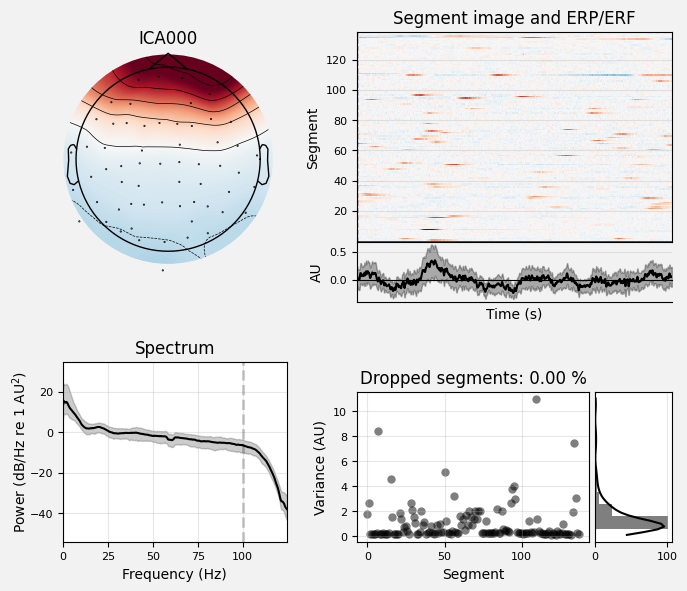

In [20]:
figs = ica.plot_properties(raw_do_ica, picks=eog_idx)

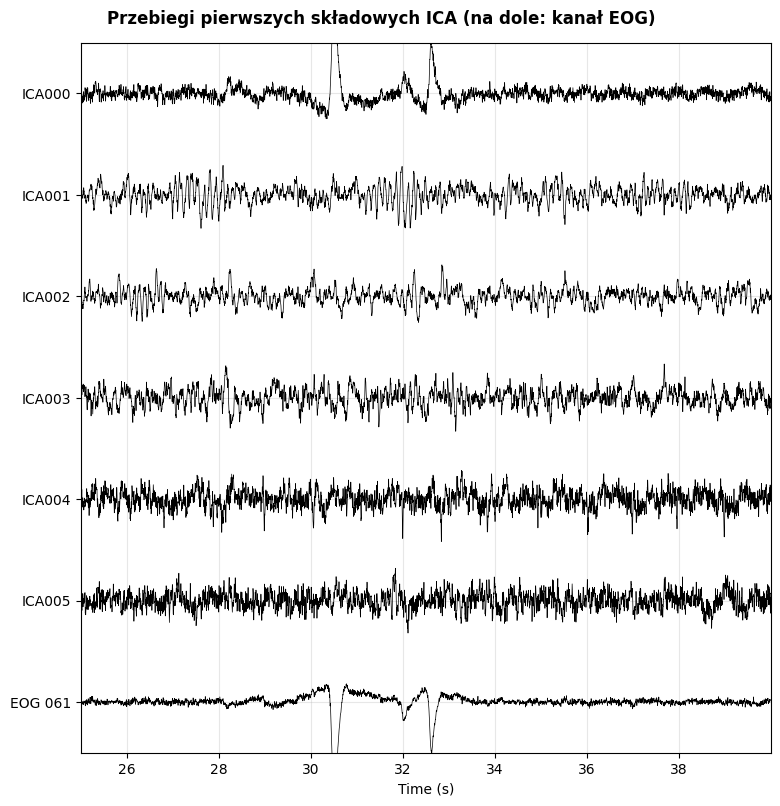

In [21]:
fig = ica.plot_sources(raw_do_ica, picks=list(range(6)), start=25, stop=40, show_scrollbars=False, show=False)
fig.suptitle("Przebiegi pierwszych składowych ICA (na dole: kanał EOG)", y=1.01, fontweight="bold")
plt.show()

### Artefakty mięśniowe

`find_bads_muscle` (kryteria Dharmaprani i in., 2016) szuka składowych, które jednocześnie:

1. mają **rosnące lub płaskie widmo** w zakresie 7–45 Hz (aktywność mózgu ma widmo malejące, ~1/f),
2. są zlokalizowane **na obrzeżach** głowy (mięśnie skroniowe, czołowe, karku),
3. mają **ogniskową**, mało gładką topografię.

Składowe mięśniowe: [7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19]


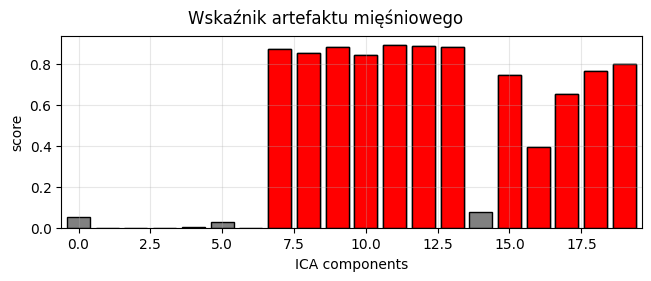

In [22]:
miesnie_idx, miesnie_wyniki = ica.find_bads_muscle(raw_do_ica)
miesnie_idx = [int(i) for i in miesnie_idx]
print("Składowe mięśniowe:", miesnie_idx)
fig = ica.plot_scores(miesnie_wyniki, exclude=miesnie_idx, title="Wskaźnik artefaktu mięśniowego")

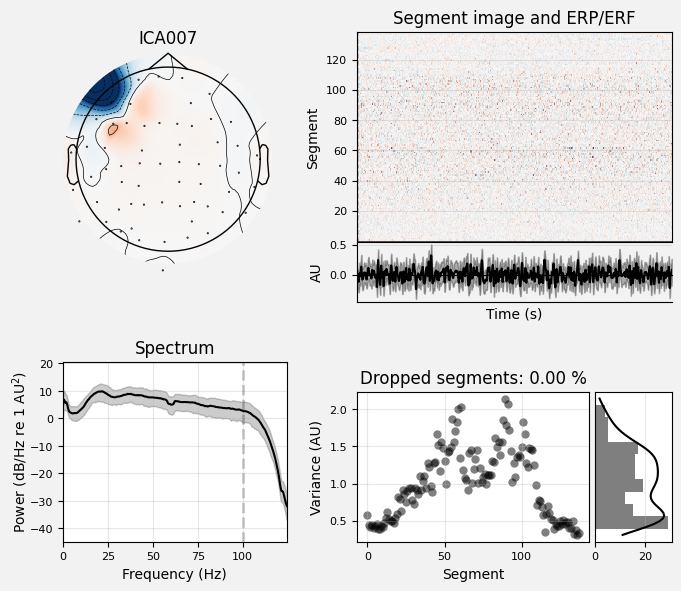

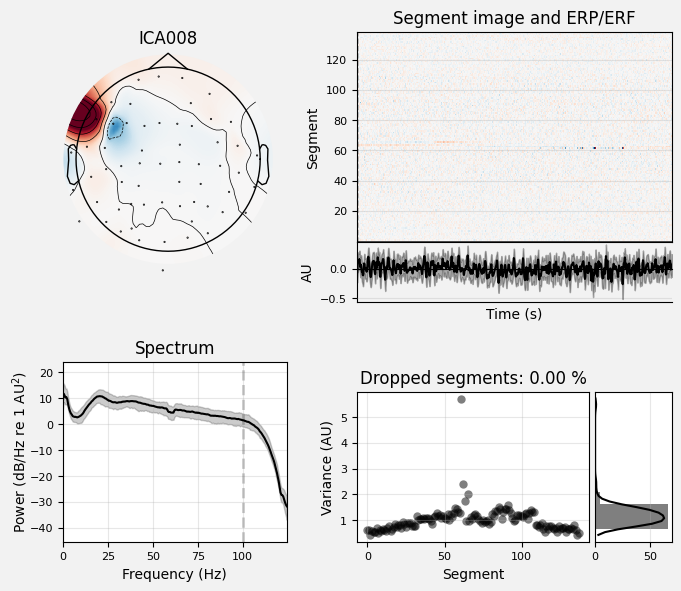

In [23]:
figs = ica.plot_properties(raw_do_ica, picks=miesnie_idx[:2])

Widmo składowych mięśniowych jest płaskie aż do wysokich częstotliwości, a topografia – mocno ogniskowa. Automatyczne kryterium jest dość liberalne (oznaczyło wiele drobnych składowych), dlatego w prawdziwej analizie każdą składową warto obejrzeć. Pomocne bywa też narzędzie ICLabel (pakiet `mne-icalabel`; Pion-Tonachini i in., 2019).

### Usunięcie artefaktów

Oznaczamy składowe do usunięcia i stosujemy ICA do danych 1–40 Hz (z tą samą referencją do średniej).

In [24]:
ica.exclude = sorted(set(eog_idx) | set(miesnie_idx))
print(f"Usuwamy {len(ica.exclude)} z {ica.n_components_} składowych: {ica.exclude}")

raw_czyste = ica.apply(raw.copy())

Usuwamy 13 z 20 składowych: [0, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19]


### Czy się udało? Średnie mrugnięcie przed i po ICA

`create_eog_epochs` wykrywa mrugnięcia w kanale EOG i wycina okna wokół nich. Uśredniony sygnał EEG wokół mrugnięcia pokazuje, jak silny jest artefakt – po ICA powinien praktycznie zniknąć.

Liczba wykrytych mrugnięć: 46


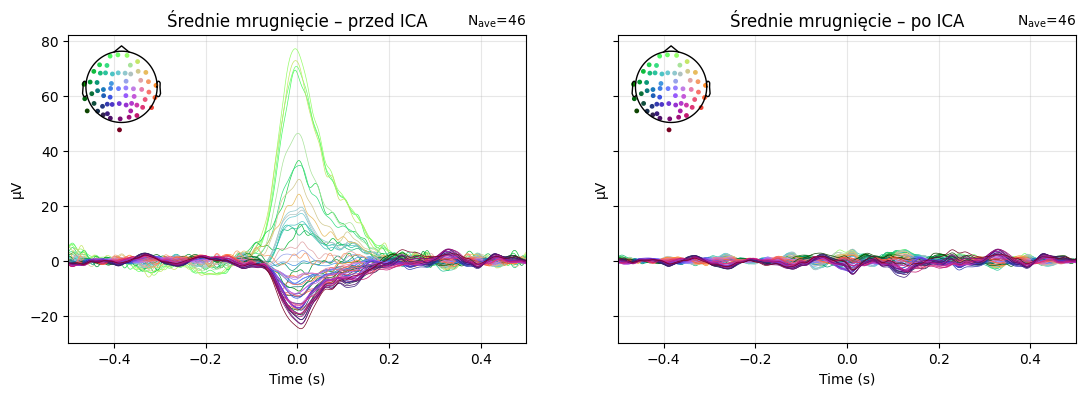

In [25]:
mrugniecia_przed = mne.preprocessing.create_eog_epochs(raw, ch_name="EOG 061", baseline=(-0.5, -0.3))
mrugniecia_po = mne.preprocessing.create_eog_epochs(raw_czyste, ch_name="EOG 061", baseline=(-0.5, -0.3))
print(f"Liczba wykrytych mrugnięć: {len(mrugniecia_przed)}")

fig, osie = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
mrugniecia_przed.average().plot(picks="eeg", axes=osie[0], show=False)
mrugniecia_po.average().plot(picks="eeg", axes=osie[1], show=False)
osie[0].set_title("Średnie mrugnięcie – przed ICA")
osie[1].set_title("Średnie mrugnięcie – po ICA")
plt.show()

I ten sam fragment sygnału z mrugnięciami – przed i po usunięciu składowych:

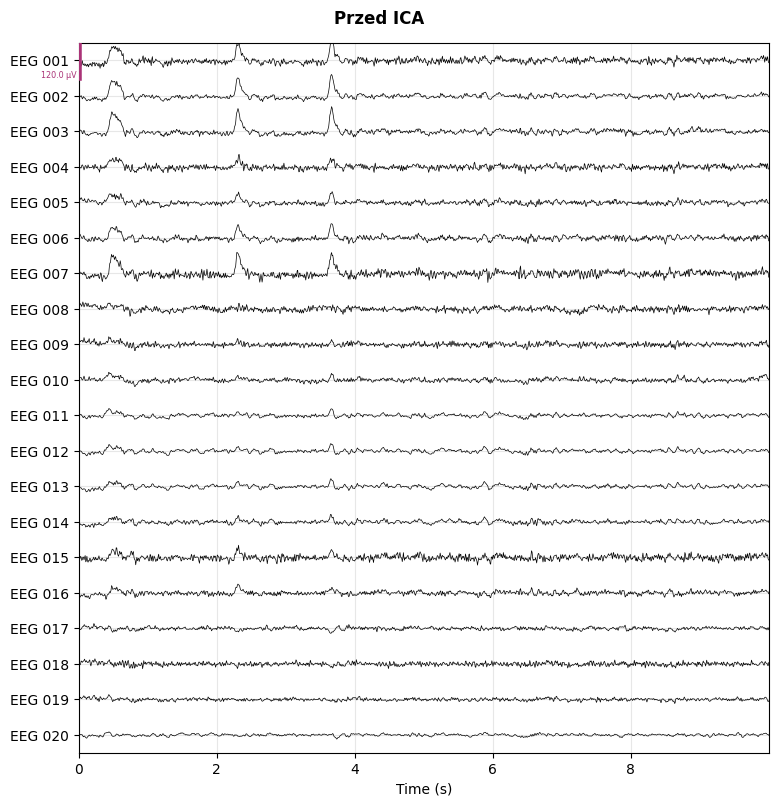

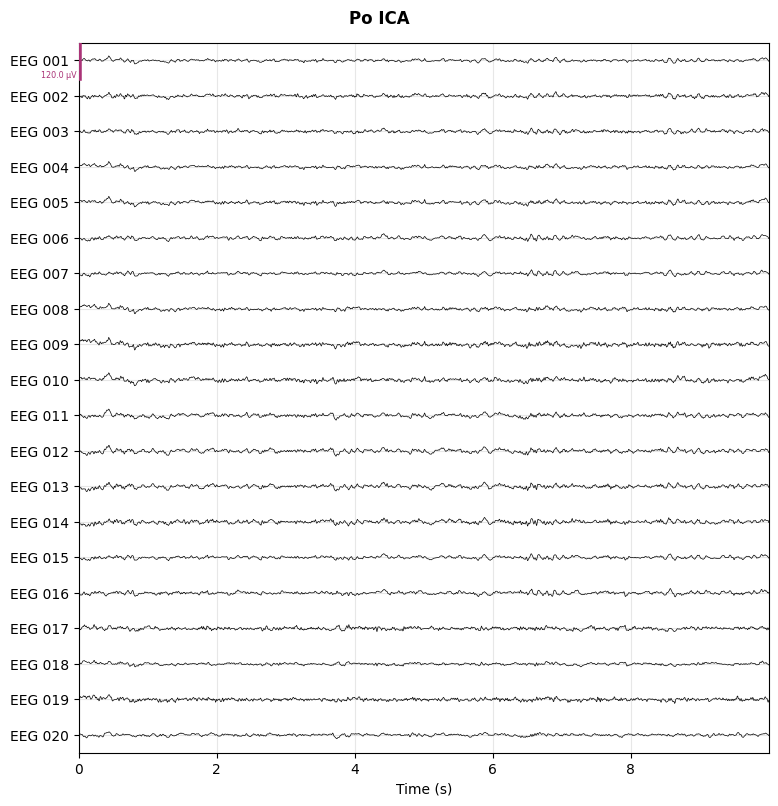

In [26]:
moment = mrugniecia_przed.events[0, 0] / raw.info["sfreq"] - raw.first_time  # pierwsze wykryte mrugnięcie [s]
for dane_eeg, tytul in [(raw, "Przed ICA"), (raw_czyste, "Po ICA")]:
    fig = dane_eeg.plot(start=max(moment - 2, 0), duration=10, n_channels=20, scalings=dict(eeg=60e-6, eog=200e-6),
                        show_scrollbars=False, show=False)
    fig.suptitle(tytul, y=1.01, fontweight="bold")
    plt.show()

## 7. Zapis wyników

Zapisujemy oczyszczone dane i rozwiązanie ICA. Z pliku `wyniki/03_sample_eeg_oczyszczone_raw.fif` skorzystamy w notebooku 04. Zgodnie z konwencją MNE nazwy plików z danymi ciągłymi kończą się na `raw.fif`, a pliki ICA – na `ica.fif` (inaczej MNE wyświetli ostrzeżenie).

In [27]:
raw_czyste.save(WYNIKI / "03_sample_eeg_oczyszczone_raw.fif", overwrite=True)
ica.save(WYNIKI / "03_sample_eeg-ica.fif", overwrite=True)
print("Zapisano:", *sorted(p.name for p in WYNIKI.glob("03_*")), sep="\n  ")

Zapisano:
  03_sample_eeg-ica.fif
  03_sample_eeg_oczyszczone_raw.fif


## 8. Dla chętnych: zapis danych w standardzie BIDS

**BIDS** (*Brain Imaging Data Structure*) to standard organizacji danych neuroobrazowych: ustalone nazwy katalogów i plików oraz pliki opisowe (`.json`, `.tsv`). Dane w BIDS łatwo udostępnić, zarchiwizować i przetwarzać gotowymi narzędziami. Pakiet **MNE-BIDS** (Appelhoff i in., 2019) zapisuje i wczytuje takie zbiory.

Zapisujemy **oryginalne**, nieprzetworzone nagranie – w BIDS przechowuje się surowe dane, a wyniki przetwarzania trafiają do osobnego katalogu `derivatives/`. Zestaw `sample` zawiera MEG i EEG, więc MNE-BIDS zapisze go jako dane MEG (wraz z kanałami EEG).

In [28]:
from mne_bids import BIDSPath, print_dir_tree, read_raw_bids, write_raw_bids

raw_oryginalny = mne.io.read_raw_fif(plik_raw, preload=False)
raw_oryginalny.info["line_freq"] = 60  # częstotliwość sieci (wymagana przez BIDS)
zdarzenia = mne.find_events(raw_oryginalny, stim_channel="STI 014")
kody_zdarzen = {"sluchowe/lewe": 1, "sluchowe/prawe": 2, "wzrokowe/lewe": 3, "wzrokowe/prawe": 4,
                "buzka": 5, "przycisk": 32}

sciezka_bids = BIDSPath(subject="01", session="01", task="audiowizualne", run="1", root=WYNIKI / "bids_sample")
write_raw_bids(raw_oryginalny, sciezka_bids, events=zdarzenia, event_id=kody_zdarzen, overwrite=True)
print_dir_tree(WYNIKI / "bids_sample")

|bids_sample/
|--- README
|--- dataset_description.json
|--- participants.json
|--- participants.tsv
|--- sub-01/
|------ ses-01/
|--------- sub-01_ses-01_scans.tsv
|--------- meg/
|------------ sub-01_ses-01_coordsystem.json
|------------ sub-01_ses-01_task-audiowizualne_run-1_channels.tsv
|------------ sub-01_ses-01_task-audiowizualne_run-1_events.json
|------------ sub-01_ses-01_task-audiowizualne_run-1_events.tsv
|------------ sub-01_ses-01_task-audiowizualne_run-1_meg.fif
|------------ sub-01_ses-01_task-audiowizualne_run-1_meg.json


In [29]:
raw_z_bids = read_raw_bids(sciezka_bids)
print(raw_z_bids)
print("Zdarzenia odczytane z pliku events.tsv:", sorted(map(str, set(raw_z_bids.annotations.description))))

<Raw | sub-01_ses-01_task-audiowizualne_run-1_meg.fif, 376 x 166800 (277.7 s), ~397 KiB, data not loaded>
Zdarzenia odczytane z pliku events.tsv: ['buzka', 'przycisk', 'sluchowe/lewe', 'sluchowe/prawe', 'wzrokowe/lewe', 'wzrokowe/prawe']


## Podsumowanie

* Obiekt `mne.io.Raw` przechowuje dane (w woltach) i metadane (`raw.info`): częstotliwość próbkowania, typy i położenia kanałów, złe kanały.
* Kolejność kroków ma znaczenie: **złe kanały naprawiamy przed re-referencją do średniej**, a ICA dopasowujemy na danych przefiltrowanych górnoprzepustowo (≥ 1 Hz).
* Filtr sieciowy dobieramy do kraju nagrania (50 Hz w Polsce, 60 Hz w USA) – po obejrzeniu widma.
* Automatyczne narzędzia (PyPREP, `find_bads_eog`, `find_bads_muscle`) przyspieszają pracę, ale ich wyniki trzeba **zweryfikować wzrokowo**.

## Zadania do samodzielnego wykonania

Pięć zadań, w których powtórzysz najważniejsze kroki z tego notebooka. **Nie wymagają nowych funkcji ani pojęć** – wszystko, czego potrzebujesz, pojawiło się wyżej (przy każdym zadaniu podajemy, którą sekcję powtarza). Każde zadanie kończy się **jednym wynikiem**: liczbą wypisaną w podanym formacie albo jedną figurą.

**Zasady pracy**

1. Zanim zaczniesz, uruchom cały notebook (**Run All**) – zadania korzystają ze zmiennych i funkcji zdefiniowanych wyżej.
2. Rozwiązanie wpisz w komórce kodu pod treścią zadania.
3. **Nie nadpisuj zmiennych z notebooka** (np. `raw`, `ica`, `raw_czyste`). Nowym zmiennym nadawaj nazwy z przedrostkiem zadania: `z1_`, `z2_`, … Dzięki temu zadania nie psują sobie nawzajem danych i nie trzeba uruchamiać notebooka od nowa.
4. **Kontrola pośrednia** to wartość, którą możesz sprawdzić po drodze. Jeśli się nie zgadza, błąd jest wcześniej – popraw go, zanim pójdziesz dalej.
5. **✅ Wynik** to jedyna rzecz do oddania: liczba wypisana dokładnie w podanym formacie (z podaną liczbą miejsc po przecinku) albo figura z podanym tytułem.
6. **Do przemyślenia** – pytanie, które pomaga zrozumieć wynik. Nie trzeba go oddawać, ale warto na nie odpowiedzieć choćby w myślach.

### Zadanie 1. Filtr sieciowy: 50 czy 60 Hz?

*Powtarzasz: sekcje 1–2 (obiekt `Raw`, widmo mocy, filtr notch).*

**Cel:** sprawdzić na liczbach, że filtr notch działa tylko wtedy, gdy trafimy w częstotliwość sieci, w której nagrano dane.

**Krok po kroku:**

1. Zmienna `raw` jest już przefiltrowana, więc wczytaj dane od nowa i zostaw tylko kanały EEG:
   `z1_raw = mne.io.read_raw_fif(plik_raw, preload=False).pick("eeg").load_data()`
2. Przygotuj dwie kopie przefiltrowane filtrem notch: jedną z `freqs=[50]`, drugą z `freqs=[60]` (sekcja 2).
3. Dla każdej z trzech wersji (bez filtra, notch 50 Hz, notch 60 Hz) policz widmo mocy: `compute_psd(fmax=200)`.
4. Z każdego widma weź moc w punkcie częstotliwości **najbliższym 60 Hz** (`np.argmin(np.abs(widmo.freqs - 60))`), policz **medianę z kanałów** i przelicz ją na decybele jak w sekcjach 2 i 4: `10 * np.log10(moc * 1e12)`.
5. Dla każdego filtra policz spadek mocy przy 60 Hz: dB bez filtra − dB po filtrze.

**Kontrola pośrednia:** filtr 50 Hz nie zmienia mocy przy 60 Hz (spadek ≈ 0,0 dB).

**✅ Wynik:** `print(f"Zadanie 1: notch 60 Hz obniżył moc przy 60 Hz o {z1_spadek_60:.1f} dB")`

**Do przemyślenia:** Ile razy spadła moc? (Spadek o 10 dB oznacza 10-krotny spadek mocy.) Co by się stało, gdyby ktoś „z przyzwyczajenia” zastosował do tych danych filtr 50 Hz?

In [30]:
# Zadanie 1 – Twoje rozwiązanie
z1_raw = mne.io.read_raw_fif(plik_raw,preload=False).pick("eeg").load_data()

harmoniczne_50 = 50 * np.arange(1, 4)
harmoniczne_60 = 60 * np.arange(1, 4)

z1_50 = z1_raw.copy().notch_filter(freqs=harmoniczne_50, picks=["eeg"])
z1_60 = z1_raw.copy().notch_filter(freqs=harmoniczne_60, picks=["eeg"])

widmo_raw = z1_raw.compute_psd(fmax=200)
widmo_50 = z1_50.compute_psd(fmax=200)
widmo_60 = z1_60.compute_psd(fmax=200)

indeks_60 = np.argmin(np.abs(widmo_raw.freqs - 60))

moc_raw = np.median(widmo_raw.get_data()[:, indeks_60])
moc_50 = np.median(widmo_50.get_data()[:, indeks_60])
moc_60 = np.median(widmo_60.get_data()[:, indeks_60])

db_raw = 10 * np.log10(moc_raw * 1e12)
db_50 = 10 * np.log10(moc_50 * 1e12)
db_60 = 10 * np.log10(moc_60 * 1e12)

print(f"Bez filtra: {db_raw} dB")
print(f"Po notchu 50 Hz: {db_50} dB")
print(f"Po notchu 60 Hz: {db_60} dB")
print(f"Róznica bez filtra minus po filtrze 50 Hz: {db_raw - db_50:.1f} dB")
print(f"Roznica bez filtra minus po filtrze 60 Hz: {db_raw - db_60} dB")

z1_spadek_50 = db_raw - db_50
z1_spadek_60 = db_raw - db_60

print(f"Zadanie 1: notch 60 Hz obniżył moc przy 60 Hz o {z1_spadek_60} dB")

Bez filtra: -8.921674813493416 dB
Po notchu 50 Hz: -8.921584086923982 dB
Po notchu 60 Hz: -24.237316898607787 dB
Róznica bez filtra minus po filtrze 50 Hz: -0.0 dB
Roznica bez filtra minus po filtrze 60 Hz: 15.315642085114371 dB
Zadanie 1: notch 60 Hz obniżył moc przy 60 Hz o 15.315642085114371 dB


### Zadanie 2. Jak dobrze działa interpolacja?

*Powtarzasz: sekcja 3 (złe kanały i interpolacja).*

**Cel:** sprawdzić jakość interpolacji na kanale, którego prawdziwy sygnał znamy.

Pomysł: bierzemy **dobry** kanał, udajemy, że jest zły, interpolujemy go i porównujemy wynik z oryginałem.

**Krok po kroku:**

1. Wczytaj dane od nowa, zostaw kanały EEG i pierwsze 60 s, przefiltruj 1–40 Hz:
   ```python
   z2_raw = mne.io.read_raw_fif(plik_raw, preload=False).pick("eeg").crop(tmax=60).load_data()
   z2_raw.filter(l_freq=1.0, h_freq=40.0)
   ```
2. Dla kanału `EEG 030` (czubek głowy, okolice Cz):
   * zapamiętaj oryginalny sygnał: `z2_raw.get_data(picks="EEG 030")[0]`,
   * zrób kopię danych (`z2_raw.copy()`) i oznacz w niej jako złe **dwa** kanały: `["EEG 053", "EEG 030"]` – kanał `EEG 053` jest naprawdę uszkodzony, więc nie może posłużyć do interpolacji,
   * zinterpoluj kopię (`interpolate_bads(reset_bads=True)`) i pobierz z niej zinterpolowany sygnał `EEG 030`,
   * policz współczynnik korelacji Pearsona oryginału z wersją zinterpolowaną: `np.corrcoef(oryginal, zinterpolowany)[0, 1]`.
3. Powtórz krok 2 dla kanału `EEG 025` (nad lewą skronią, na brzegu czepka). Najwygodniej zrobić to w pętli po obu kanałach.

**Kontrola pośrednia:** dla `EEG 030` korelacja wynosi ok. 0,99.

**✅ Wynik:** `print(f"Zadanie 2: r(EEG 025) = {z2_r['EEG 025']:.2f}")`

**Do przemyślenia:** Dlaczego elektroda na brzegu czepka jest odtwarzana gorzej? (Z ilu stron ma sąsiadów?) Co z tego wynika dla pomysłu, by zinterpolować wszystkie kanały czołowe i skroniowe wskazane przez PyPREP?

In [31]:
# Zadanie 2 – Twoje rozwiązanie
z2_raw = mne.io.read_raw_fif(plik_raw, preload=False).pick("eeg").crop(tmax=60).load_data()
z2_raw.filter(l_freq=1.0,h_freq=40.0)

z2_raw.get_data(picks="EEG 030")[0]

z2_r={}

for kanal in ["EEG 030", "EEG 025"]:
    oryginal = z2_raw.get_data(picks=kanal)[0]

    z2_interpolacja = z2_raw.copy()
    z2_interpolacja.info["bads"] = ["EEG 053", kanal]
    z2_interpolacja.interpolate_bads(reset_bads=True)

    zinterpolowany = z2_interpolacja.get_data(picks=kanal)[0]

    z2_r[kanal] = np.corrcoef(oryginal, zinterpolowany)[0, 1]




print(f"Zadanie 2: r(EEG 025) = {z2_r['EEG 025']:.2f}")

Zadanie 2: r(EEG 025) = 0.88


### Zadanie 3. Długość filtra górnoprzepustowego

*Powtarzasz: sekcja 4 (filtracja pasmowoprzepustowa, filtr FIR).*

**Cel:** zobaczyć, jak dolna częstotliwość odcięcia wpływa na długość filtra FIR – i zrozumieć, dlaczego filtrujemy ciągły zapis, a nie krótkie epoki.

**Krok po kroku:**

1. Funkcją `mne.filter.create_filter` (sekcja 4) utwórz filtry pasmowe z górną granicą `h_freq=40.0` i czterema wartościami dolnej granicy `l_freq`: 2, 1, 0,5 i 0,1 Hz. Jako częstotliwość próbkowania podaj `raw.info["sfreq"]`, a jako dane – `None` (tak jak w notebooku).
2. Funkcja zwraca współczynniki filtra (tablicę NumPy). Długość filtra w próbkach to `len(filtr)`, a w sekundach – `len(filtr) / raw.info["sfreq"]`.
3. Dla każdego filtra wypisz w pętli: `l_freq`, długość w próbkach i długość w sekundach.

**Kontrola pośrednia:** filtr 1–40 Hz z notebooka ma 1983 współczynniki (3,3 s).

**✅ Wynik:** `print(f"Zadanie 3: filtr 0,1–40 Hz trwa {z3_dlugosc_01:.1f} s")`

**Do przemyślenia:** Jak zmienia się długość filtra, gdy `l_freq` maleje 10-krotnie? Dlaczego filtr górnoprzepustowy 0,1 Hz stosujemy do ciągłego zapisu, a nie do wyciętych epok trwających np. 0,7 s?

In [48]:
wartosci = [2.0, 1.0, 0.5, 0.1]
wyniki = {}

for wartosc in wartosci:
    krok = mne.filter.create_filter(None, raw.info["sfreq"], l_freq=wartosc, h_freq=40.0)
    dlugosc = len(krok)
    dlugosc_s = dlugosc / raw.info["sfreq"]
    wyniki[wartosc] = (dlugosc, dlugosc_s)

    print(f"l_freq = {wartosc}, długość = {dlugosc}, długość w sekundach = {dlugosc_s:.1f}")

z3_dlugosc_01 = wyniki[0.1][1]
print(f"Zadanie 3: filtr 0,1–40 Hz trwa {z3_dlugosc_01:.1f} s")

l_freq = 2.0, długość = 993, długość w sekundach = 1.7
l_freq = 1.0, długość = 1983, długość w sekundach = 3.3
l_freq = 0.5, długość = 3965, długość w sekundach = 6.6
l_freq = 0.1, długość = 19821, długość w sekundach = 33.0
Zadanie 3: filtr 0,1–40 Hz trwa 33.0 s


### Zadanie 4. Zła elektroda a referencja do średniej

*Powtarzasz: sekcje 3 i 5 (interpolacja złych kanałów, re-referencja do średniej).*

**Cel:** sprawdzić na liczbach, dlaczego złe kanały naprawiamy **przed** re-referencją do średniej.

**Krok po kroku:**

1. Przygotuj dane tak jak w Zadaniu 2, krok 1 (EEG, pierwsze 60 s, filtr 1–40 Hz), ale w nowej zmiennej `z4_raw`.
2. Zasymuluj uszkodzoną elektrodę: dodaj do kanału `EEG 010` silne zakłócenie – sinusoidę 7 Hz o amplitudzie 500 µV. Robimy to tak samo jak przy sztucznym zakłóceniu 50 Hz w sekcji 2:
   ```python
   z4_raw.apply_function(lambda x: x + 500e-6 * np.sin(2 * np.pi * 7 * z4_raw.times), picks=["EEG 010"])
   ```
3. **Wariant A** („zapomnieliśmy o złym kanale”): kopia `z4_raw` → od razu referencja do średniej: `set_eeg_reference("average", projection=False)`.
4. **Wariant B** („poprawna kolejność”): kopia `z4_raw` → oznacz `["EEG 053", "EEG 010"]` jako złe → interpolacja (`interpolate_bads(reset_bads=True)`) → dopiero teraz referencja do średniej.
5. W obu wariantach policz odchylenie standardowe (w µV) każdego kanału **oprócz** `EEG 010` i `EEG 053`, a potem **medianę** tych odchyleń. *Wskazówka:* lista kanałów: `[k for k in z4_A.ch_names if k not in ("EEG 010", "EEG 053")]`, a odchylenia: `get_data(picks=lista).std(axis=1)` (jak w sekcji 3).

**Kontrola pośrednia:** w wariancie B mediana wynosi ok. 5,3 µV – praktycznie tyle samo co w danych bez zakłócenia.

**✅ Wynik:** `print(f"Zadanie 4: wariant A = {z4_mediana_A:.1f} µV")`

**Do przemyślenia:** Zakłócenie było tylko w jednym kanale – skąd wzrost odchylenia we wszystkich pozostałych? Jaką amplitudę ma „rozlana” sinusoida w każdym kanale po referencji do średniej? (Podziel 500 µV przez liczbę kanałów użytych do średniej.)

In [49]:
# Zadanie 4 – Twoje rozwiązanie
z4_raw = mne.io.read_raw_fif(plik_raw, preload=False).pick("eeg").crop(tmax=60).load_data()
z4_raw.filter(l_freq=1.0,h_freq=40.0)

z4_raw.apply_function(lambda x: x + 500e-6 * np.sin(2 * np.pi * 7 * z4_raw.times), picks=["EEG 010"])

#Wariant A

z4_A = z4_raw.copy().set_eeg_reference("average", projection=False)
z4_srednia_A = z4_A.get_data(picks="eeg").mean(axis=0)

oprocz_A = [k for k in z4_A.ch_names if k not in ("EEG 010", "EEG 053")]
z4_odch_A = z4_A.get_data(picks=oprocz_A).std(axis=1) * 1e6
z4_mediana_A = np.median(z4_odch_A)

#Wariant B
z4_B = z4_raw.copy()

z4_B.info["bads"] = ["EEG 053","EEG 010"] 
z4_B.interpolate_bads(reset_bads=True)
z4_B.set_eeg_reference("average", projection=False)
z4_srednia_B = z4_B.get_data(picks="eeg").mean(axis=0)

oprocz_B = [k for k in z4_B.ch_names if k not in ("EEG 010", "EEG 053")]
z4_odch_B = z4_B.get_data(picks=oprocz_B).std(axis=1) * 1e6
z4_mediana_B = np.median(z4_odch_B)

print(f"Kontrola posrednia {z4_mediana_B}")
print(f"Zadanie 4: wariant A = {z4_mediana_A:.1f} µV")

Kontrola posrednia 5.342540899095072
Zadanie 4: wariant A = 8.1 µV


### Zadanie 5. Ile mrugnięcia zostało po ICA?

*Powtarzasz: sekcja 6 („Czy się udało? Średnie mrugnięcie przed i po ICA”).*

**Cel:** zamienić porównanie „na oko” (wykresy średniego mrugnięcia) na jedną liczbę.

**Krok po kroku:**

1. Skorzystaj z obiektów `mrugniecia_przed` i `mrugniecia_po` z sekcji 6 i uśrednij każdy z nich (`average()`).
2. Z każdej średniej pobierz sygnał kanału `EEG 003` (elektroda czołowa, tuż nad oczami) w µV: `evoked.get_data(picks="EEG 003")[0] * 1e6`.
3. Policz **amplitudę międzyszczytową** średniego mrugnięcia: maksimum minus minimum sygnału w całej epoce – przed ICA i po ICA.
4. Policz, o ile procent ICA zmniejszyła tę amplitudę: `100 * (1 - po / przed)`.

**Kontrola pośrednia:** przed ICA amplituda międzyszczytowa w `EEG 003` wynosi ok. 82,5 µV.

**✅ Wynik:** `print(f"Zadanie 5: ICA zmniejszyła mrugnięcie w EEG 003 o {z5_procent:.0f}%")`

**Do przemyślenia:** Czy pozostałe kilka mikrowoltów to resztka mrugnięcia, czy zwykła aktywność EEG? (Porównaj z odchyleniem standardowym kanałów z sekcji 3.) Czy składowe mięśniowe miały tu jakiekolwiek znaczenie?

In [52]:
# Zadanie 5 – Twoje rozwiązanie
sr_przed = mrugniecia_przed.average()
sr_po = mrugniecia_po.average()

sygnal_przed = sr_przed.get_data(picks="EEG 003")[0] * 1e6
sygnal_po = sr_po.get_data(picks="EEG 003")[0] * 1e6

z5_amplituda_przed = sygnal_przed.max() - sygnal_przed.min()
z5_amplituda_po = sygnal_po.max() - sygnal_po.min()
z5_procent = 100 * (1 - z5_amplituda_po / z5_amplituda_przed)

print(f"Amplituda przed: {z5_amplituda_przed}")
print(f"Zadanie 5: ICA zmniejszyła mrugnięcie w EEG 003 o {z5_procent:.0f}%")

Amplituda przed: 82.53842968263416
Zadanie 5: ICA zmniejszyła mrugnięcie w EEG 003 o 92%


## Literatura

* Appelhoff, S., Sanderson, M., Brooks, T. L., i in. (2019). MNE-BIDS: Organizing electrophysiological data into the BIDS format and facilitating their analysis. *Journal of Open Source Software, 4*(44), 1896.
* Bigdely-Shamlo, N., Mullen, T., Kothe, C., Su, K.-M., i Robbins, K. A. (2015). The PREP pipeline: Standardized preprocessing for large-scale EEG analysis. *Frontiers in Neuroinformatics, 9*, 16.
* Dharmaprani, D., Nguyen, H. K., Lewis, T. W., i in. (2016). A comparison of independent component analysis algorithms and measures to discriminate between EEG and artifact components. *38th Annual International Conference of the IEEE EMBC*, 825–828.
* Gramfort, A., Luessi, M., Larson, E., i in. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience, 7*, 267.
* Pion-Tonachini, L., Kreutz-Delgado, K., i Makeig, S. (2019). ICLabel: An automated electroencephalographic independent component classifier, dataset, and website. *NeuroImage, 198*, 181–197.
* Widmann, A., Schröger, E., i Maess, B. (2015). Digital filter design for electrophysiological data – a practical approach. *Journal of Neuroscience Methods, 250*, 34–46.
* Winkler, I., Debener, S., Müller, K.-R., i Tangermann, M. (2015). On the influence of high-pass filtering on ICA-based artifact reduction in EEG-ERP. *37th Annual International Conference of the IEEE EMBC*, 4101–4105.